# Práctica Evaluativa 2 · Notebook 2: Regresión logística
### Breast Cancer Wisconsin Diagnostic: clasificación con una sola variable (`radius_mean`)

| | |
|---|---|
| **Universidad** | Universidad Cooperativa de Colombia |
| **Programa** | Ingeniería de Software |
| **Asignatura** | Analítica de Datos |
| **Docente** | Luis Miguel Gómez Meneses |
| **Práctica** | Práctica Evaluativa 2: regresión lineal, comparación de medias y clasificación |
| **Autor(es)** | Santiago Rodriguez Jimenez y Alexander Mejia Ospina |
| **Base de datos** | `data.csv` (suministrada por el docente) |

**Pregunta central:** ¿qué tan bien permite el radio medio distinguir observaciones benignas y malignas?

**Ruta del notebook:**
1. Librerías
2. Carga de los datos
3. Contexto y comprensión de los datos
4. Calidad de los datos (columna vacía, `id`, codificación de `diagnosis`)
5. Exploración de `radius_mean` por clase
6. División 80/20 estratificada
7. Entrenamiento con una sola variable, probabilidades, curva sigmoide y umbral 0,5
8. Evaluación en prueba: matriz de confusión, métricas, casos individuales y preguntas de reflexión
9. Análisis opcional con otra variable (permitido por el docente)
10. Conclusión

## 1. Librerías

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

sns.set_theme(style='whitegrid')

SEMILLA = 42   # semilla fija para la división

El archivo `data.csv` se sube directamente a Colab (panel de archivos de la izquierda, botón de subir) antes de ejecutar la celda. En local, el CSV debe estar en la misma carpeta del notebook.

In [29]:
df = pd.read_csv('data.csv')   # el CSV se sube al panel de archivos de Colab (o va junto al notebook en local)
print('Dimensiones:', df.shape)
df[['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean']].head()

Dimensiones: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean
0,842302,M,17.99,10.38,122.80,1001.0
1,842517,M,20.57,17.77,132.90,1326.0
2,84300903,M,19.69,21.25,130.00,1203.0
3,84348301,M,11.42,20.38,77.58,386.1
4,84358402,M,20.29,14.34,135.10,1297.0


## 3. Contexto y comprensión de los datos

Cada fila es una muestra de una masa mamaria. A partir de una imagen digitalizada de la muestra se midieron características de los **núcleos celulares** (radio, textura, perímetro, área, suavidad, concavidad, etc.). De cada característica hay tres versiones: la media (`_mean`), el error estándar (`_se`) y el peor valor (`_worst`). La columna `diagnosis` dice si la muestra resultó **benigna (B)** o **maligna (M)**.

En esta práctica solo se usa **`radius_mean`**, el radio medio de los núcleos, como variable de entrada.

In [30]:
print('Filas:', df.shape[0], '| Columnas:', df.shape[1])
print('\nColumnas numéricas:', df.select_dtypes(include='number').shape[1])
print('Columnas de texto:', list(df.select_dtypes(exclude='number').columns))
print('\nÚltimas columnas del archivo:', list(df.columns[-3:]))
print('\nTipo de radius_mean:', df['radius_mean'].dtype)

Filas: 569 | Columnas: 33

Columnas numéricas: 32
Columnas de texto: ['diagnosis']

Últimas columnas del archivo: ['symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Tipo de radius_mean: float64


El archivo tiene **569 observaciones y 33 columnas**: `id`, `diagnosis` (texto), las 30 mediciones numéricas y una columna extra llamada `Unnamed: 32`, que no aparece en la descripción de la base. Se revisa a continuación.

## 4. Calidad de los datos

In [31]:
faltantes = df.isna().sum()
print('Columnas con valores faltantes:')
print(faltantes[faltantes > 0])

print('\nFilas duplicadas:', df.duplicated().sum())
print('IDs repetidos:', df['id'].duplicated().sum())

Columnas con valores faltantes:
Unnamed: 32    569
dtype: int64

Filas duplicadas: 0
IDs repetidos: 0


In [32]:
# ¿Unnamed: 32 está completamente vacía?
print('Valores no nulos en Unnamed: 32:', df['Unnamed: 32'].notna().sum(), 'de', len(df))
print('¿Está totalmente vacía?', df['Unnamed: 32'].isna().all())

Valores no nulos en Unnamed: 32: 0 de 569
¿Está totalmente vacía? True


- **`Unnamed: 32`** tiene los 569 valores vacíos. Aparece porque la fila de encabezados del CSV termina en una coma, y pandas crea una columna sin nombre. No tiene ninguna información, así que **se elimina**.
- **`id`** es solo un identificador de cada muestra: no describe nada de las células. **Se excluye de las entradas del modelo**, porque cualquier relación entre el número de `id` y el diagnóstico sería casualidad.
- Fuera de `Unnamed: 32` **no hay faltantes**, y no hay filas ni IDs duplicados, así que no hace falta imputar ni eliminar registros.

In [33]:
df = df.drop(columns=['Unnamed: 32'])
print('Dimensiones después de eliminar Unnamed: 32:', df.shape)
print('Faltantes que quedan en toda la base:', df.isna().sum().sum())

Dimensiones después de eliminar Unnamed: 32: (569, 32)
Faltantes que quedan en toda la base: 0


In [34]:
df['radius_mean'].describe().round(3)

,radius_mean
count,569.000
mean,14.127
std,3.524
min,6.981
25%,11.700
50%,13.370
75%,15.780
max,28.110


`radius_mean` va de 6,98 a 28,11, todos los valores son positivos y no hay vacíos. Los valores altos no se tratan como errores: un radio grande es justamente una característica que se espera en algunas muestras malignas, así que eliminarlos le quitaría al modelo información útil.

In [35]:
conteo = df['diagnosis'].value_counts()
proporcion = df['diagnosis'].value_counts(normalize=True)
distribucion = pd.DataFrame({'n': conteo, 'porcentaje': (proporcion * 100).round(1)})
print('Distribución de diagnosis:')
distribucion

Distribución de diagnosis:


,n,porcentaje
diagnosis,,
B,357,62.7
M,212,37.3


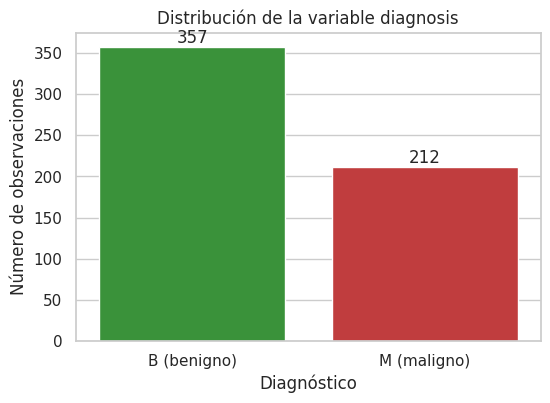

In [36]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='diagnosis', hue='diagnosis', order=['B', 'M'],
                   palette={'B': 'tab:green', 'M': 'tab:red'}, legend=False)
for barra in ax.patches:
    ax.annotate(f'{int(barra.get_height())}', (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha='center', va='bottom')
plt.xticks([0, 1], ['B (benigno)', 'M (maligno)'])
plt.xlabel('Diagnóstico')
plt.ylabel('Número de observaciones')
plt.title('Distribución de la variable diagnosis')
plt.show()

Hay **357 benignos (62,7 %) y 212 malignos (37,3 %)**. Las clases no están equilibradas: hay casi dos benignos por cada maligno. Esto se tiene en cuenta en la división (estratificación) y al leer la exactitud.

### Codificación de la variable objetivo

Se codifica **B = 0** y **M = 1**, así la clase positiva (la que interesa detectar) es maligno.

In [37]:
df['diagnosis_num'] = df['diagnosis'].map({'B': 0, 'M': 1})

# Comprobación de la correspondencia entre la etiqueta original y el número
pd.crosstab(df['diagnosis'], df['diagnosis_num'], rownames=['diagnosis original'], colnames=['codificado'])

codificado,0,1
diagnosis original,,
B,357,0
M,0,212


La tabla cruzada confirma que las 357 observaciones B quedaron como 0 y las 212 M quedaron como 1, sin ningún caso cruzado ni vacío.

## 5. Exploración de `radius_mean` en cada clase

In [38]:
df.groupby('diagnosis')['radius_mean'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
diagnosis,,,,,,,,
B,357.0,12.15,1.78,6.98,11.08,12.20,13.37,17.85
M,212.0,17.46,3.20,10.95,15.08,17.33,19.59,28.11


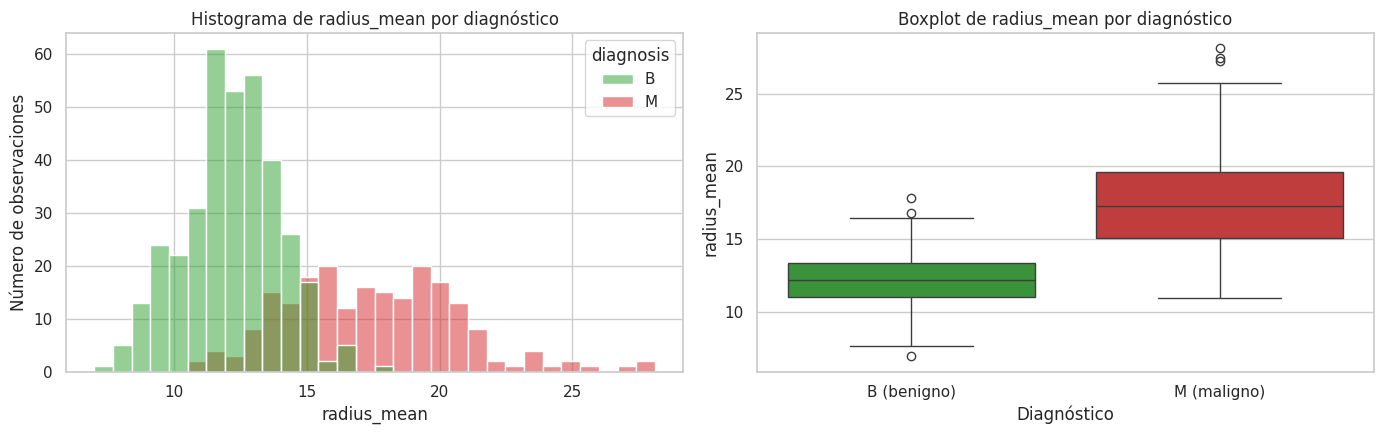

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=df, x='radius_mean', hue='diagnosis', hue_order=['B', 'M'],
             palette={'B': 'tab:green', 'M': 'tab:red'}, bins=30, alpha=0.5, ax=axes[0])
axes[0].set_xlabel('radius_mean')
axes[0].set_ylabel('Número de observaciones')
axes[0].set_title('Histograma de radius_mean por diagnóstico')

sns.boxplot(data=df, x='diagnosis', y='radius_mean', hue='diagnosis', order=['B', 'M'],
            palette={'B': 'tab:green', 'M': 'tab:red'}, legend=False, ax=axes[1])
axes[1].set_xticks([0, 1], ['B (benigno)', 'M (maligno)'])
axes[1].set_xlabel('Diagnóstico')
axes[1].set_ylabel('radius_mean')
axes[1].set_title('Boxplot de radius_mean por diagnóstico')

plt.tight_layout()
plt.show()

In [40]:
minimo_maligno = df.loc[df['diagnosis_num'] == 1, 'radius_mean'].min()
maximo_benigno = df.loc[df['diagnosis_num'] == 0, 'radius_mean'].max()
zona = df[(df['radius_mean'] >= minimo_maligno) & (df['radius_mean'] <= maximo_benigno)]

print(f'Zona de superposición: radius_mean entre {minimo_maligno} y {maximo_benigno}')
print(f'Observaciones dentro de esa zona: {len(zona)} de {len(df)}')
print(zona['diagnosis'].value_counts())

Zona de superposición: radius_mean entre 10.95 y 17.85
Observaciones dentro de esa zona: 390 de 569
diagnosis
B    275
M    115
Name: count, dtype: int64


**¿Hay superposición entre las clases?** Sí, y bastante. Los malignos tienen en promedio un radio mucho mayor (17,46 frente a 12,15), así que `radius_mean` sí ayuda a separar. Pero los rangos se cruzan: el maligno más pequeño mide 10,95 y el benigno más grande 17,85. Entre esos dos valores quedan **390 de las 569 observaciones** (275 benignas y 115 malignas). Fuera de esa franja la clase es clara (radios menores de 10,95 solo son benignos y mayores de 17,85 solo malignos), pero adentro el radio solo no alcanza para decidir con seguridad. **Por eso ya se puede anticipar que el modelo va a cometer errores**, sobre todo con malignos de radio pequeño.

Esta exploración es solo descriptiva: ningún parámetro del modelo sale de aquí.

## 6. División 80 % entrenamiento / 20 % prueba (estratificada)

Se usa la semilla 42 y `stratify` por la variable objetivo para que las dos partes tengan casi la misma proporción de benignos y malignos.

In [41]:
X = df[['radius_mean']]      # única variable predictora
y = df['diagnosis_num']      # 0 = benigno, 1 = maligno

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEMILLA, stratify=y)

print(f'Entrenamiento: {len(X_train)} observaciones | Prueba: {len(X_test)} observaciones')
proporciones = pd.DataFrame({
    'Total': y.value_counts(normalize=True),
    'Entrenamiento': y_train.value_counts(normalize=True),
    'Prueba': y_test.value_counts(normalize=True),
}).rename(index={0: '0 = benigno', 1: '1 = maligno'})
(proporciones * 100).round(1)

Entrenamiento: 455 observaciones | Prueba: 114 observaciones


,Total,Entrenamiento,Prueba
diagnosis_num,,,
0 = benigno,62.7,62.6,63.2
1 = maligno,37.3,37.4,36.8


Las proporciones quedaron prácticamente iguales (alrededor de 63 % benignos y 37 % malignos en las tres columnas), así que la estratificación funcionó. En prueba quedan 72 benignos y 42 malignos.

## 7. Entrenamiento de la regresión logística con una sola variable

**¿Se estandariza `radius_mean`?** No. Como el modelo tiene una sola variable, no hay que poner varias variables en una escala común, y dejarla en sus unidades originales permite interpretar directamente el coeficiente y el punto de corte. Se usa `LogisticRegression` con los valores por defecto de scikit-learn (incluye una regularización L2 suave, C = 1).

In [42]:
modelo = LogisticRegression()
modelo.fit(X_train, y_train)      # se entrena SOLO con entrenamiento

b0 = modelo.intercept_[0]
b1 = modelo.coef_[0][0]
corte = -b0 / b1                  # radio donde la probabilidad estimada es 0,5

print(f'Intercepto (b0): {b0:.4f}')
print(f'Coeficiente de radius_mean (b1): {b1:.4f}')
print(f'\nEcuación: P(maligno) = 1 / (1 + e^-({b0:.4f} + {b1:.4f} * radius_mean))')
print(f'Razón de odds por cada unidad de radio: e^b1 = {np.exp(b1):.2f}')
print(f'Radio donde P(maligno) = 0,5: {corte:.2f}')

Intercepto (b0): -14.9158
Coeficiente de radius_mean (b1): 1.0085

Ecuación: P(maligno) = 1 / (1 + e^-(-14.9158 + 1.0085 * radius_mean))
Razón de odds por cada unidad de radio: e^b1 = 2.74
Radio donde P(maligno) = 0,5: 14.79


**Interpretación:**

- El coeficiente es **positivo (1,0085)**: a mayor radio medio, mayor probabilidad de que la muestra sea maligna.
- e^1,0085 ≈ **2,74**: cada unidad adicional de `radius_mean` multiplica por 2,74 los odds (la razón entre la probabilidad de maligno y la de benigno).
- El modelo pasa la probabilidad de 0,5 cuando el radio es **14,79**. Con el umbral de 0,5, eso significa que en la práctica el modelo clasifica como maligna toda muestra con radio de 14,79 o más, y como benigna las de menor radio.

### Probabilidades: ¿qué columna corresponde a maligno?

`predict_proba` devuelve dos columnas, una por clase, en el orden que indica `modelo.classes_`.

In [43]:
print('Orden de las clases en el modelo:', modelo.classes_)

prob_test = modelo.predict_proba(X_test)
vista = pd.DataFrame(prob_test, columns=['P(clase 0 = benigno)', 'P(clase 1 = maligno)'], index=X_test.index)
vista.insert(0, 'radius_mean', X_test['radius_mean'])
vista['suma'] = vista['P(clase 0 = benigno)'] + vista['P(clase 1 = maligno)']
vista.sort_values('radius_mean').iloc[[0, 1, 56, 57, -2, -1]].round(4)

Orden de las clases en el modelo: [0 1]


,radius_mean,P(clase 0 = benigno),P(clase 1 = maligno),suma
568,7.760,0.9992,0.0008,1.0
314,8.597,0.9981,0.0019,1.0
455,13.380,0.8056,0.1944,1.0
39,13.480,0.7893,0.2107,1.0
393,21.610,0.0010,0.9990,1.0
503,23.090,0.0002,0.9998,1.0


`classes_` es `[0 1]`, entonces **la columna de índice 1 es la probabilidad de maligno**. En la tabla se ve que esa columna sube a medida que aumenta el radio (casi 0 en los radios pequeños y casi 1 en los grandes), y que las dos columnas siempre suman 1. A partir de aquí solo se usa la columna 1.

In [44]:
prob_maligno_test = prob_test[:, 1]

### Curva sigmoide

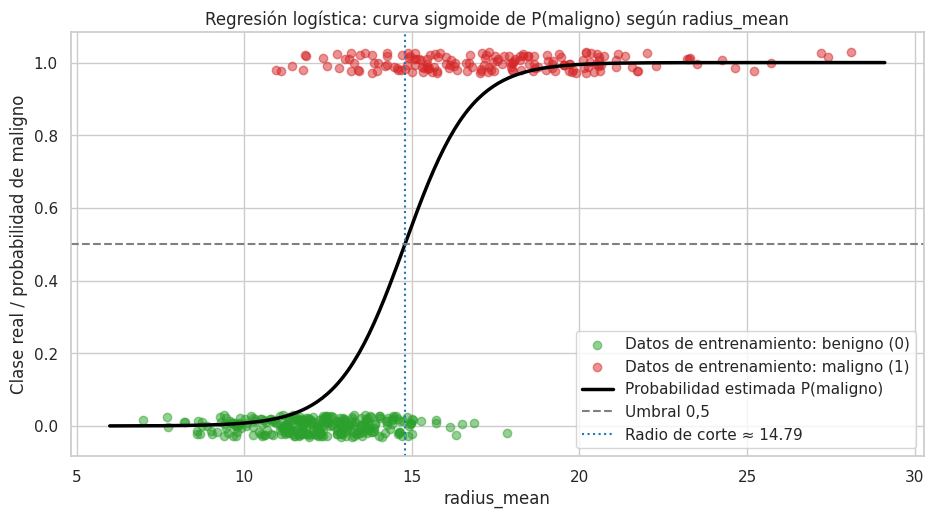

In [45]:
radios = np.linspace(df['radius_mean'].min() - 1, df['radius_mean'].max() + 1, 300)
prob_curva = modelo.predict_proba(pd.DataFrame({'radius_mean': radios}))[:, 1]

# Pequeño desplazamiento vertical aleatorio solo para que los puntos no queden encima unos de otros
rng = np.random.default_rng(SEMILLA)
jitter = rng.uniform(-0.03, 0.03, len(y_train))

plt.figure(figsize=(11, 5.5))
plt.scatter(X_train.loc[y_train == 0, 'radius_mean'], y_train[y_train == 0] + jitter[y_train.values == 0],
            color='tab:green', alpha=0.5, label='Datos de entrenamiento: benigno (0)')
plt.scatter(X_train.loc[y_train == 1, 'radius_mean'], y_train[y_train == 1] + jitter[y_train.values == 1],
            color='tab:red', alpha=0.5, label='Datos de entrenamiento: maligno (1)')
plt.plot(radios, prob_curva, color='black', linewidth=2.5, label='Probabilidad estimada P(maligno)')
plt.axhline(0.5, color='gray', linestyle='--', label='Umbral 0,5')
plt.axvline(corte, color='tab:blue', linestyle=':', label=f'Radio de corte ≈ {corte:.2f}')
plt.xlabel('radius_mean')
plt.ylabel('Clase real / probabilidad de maligno')
plt.title('Regresión logística: curva sigmoide de P(maligno) según radius_mean')
plt.legend(loc='lower right')
plt.show()

La curva negra es la probabilidad estimada y los puntos son los datos reales (abajo los benignos en 0, arriba los malignos en 1). La curva tiene forma de **S**: con radios menores de 11 la probabilidad es casi 0, con radios mayores de 19 es casi 1, y la subida fuerte ocurre entre 12 y 18. Justo en esa franja hay puntos verdes y rojos mezclados, que es donde el modelo se va a equivocar.

### De probabilidades a clases con el umbral 0,5

Regla: si P(maligno) ≥ 0,5 se predice la clase 1 (maligno); si es menor, la clase 0 (benigno).

In [46]:
UMBRAL = 0.5
y_pred = (prob_maligno_test >= UMBRAL).astype(int)

print('Predicciones en prueba:', pd.Series(y_pred).value_counts().rename({0: 'benigno (0)', 1: 'maligno (1)'}).to_dict())

Predicciones en prueba: {'benigno (0)': 78, 'maligno (1)': 36}


## 8. Evaluación con el conjunto de prueba

Todo lo de esta sección usa **solo las 114 observaciones de prueba**, que el modelo no vio durante el entrenamiento.

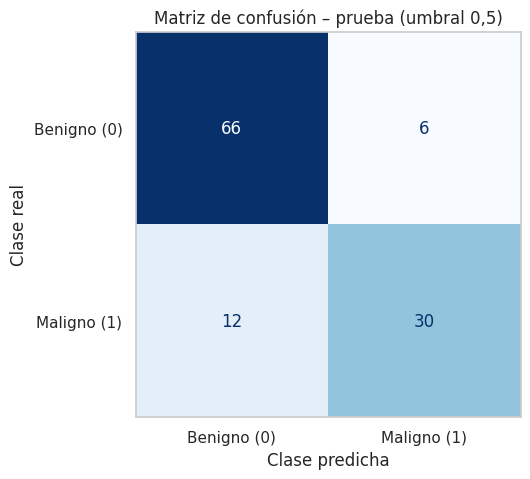

Verdaderos negativos (VN): 66
Falsos positivos (FP):     6
Falsos negativos (FN):     12
Verdaderos positivos (VP): 30


In [47]:
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matriz, display_labels=['Benigno (0)', 'Maligno (1)']).plot(cmap='Blues', ax=ax, colorbar=False)
ax.set_xlabel('Clase predicha')
ax.set_ylabel('Clase real')
ax.set_title('Matriz de confusión – prueba (umbral 0,5)')
ax.grid(False)
plt.show()

tn, fp, fn, tp = matriz.ravel()
print(f'Verdaderos negativos (VN): {tn}')
print(f'Falsos positivos (FP):     {fp}')
print(f'Falsos negativos (FN):     {fn}')
print(f'Verdaderos positivos (VP): {tp}')

In [48]:
exactitud = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
sensibilidad = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

metricas = pd.DataFrame({
    'Métrica': ['Exactitud', 'Precisión', 'Sensibilidad (recall)', 'F1'],
    'Fórmula': ['(VP + VN) / total', 'VP / (VP + FP)', 'VP / (VP + FN)', '2·P·S / (P + S)'],
    'Cálculo': [f'({tp} + {tn}) / {len(y_test)}', f'{tp} / ({tp} + {fp})', f'{tp} / ({tp} + {fn})',
                f'2·{precision:.3f}·{sensibilidad:.3f} / ({precision:.3f} + {sensibilidad:.3f})'],
    'Valor': [exactitud, precision, sensibilidad, f1],
})
print('MÉTRICAS EN PRUEBA (clase positiva = maligno)')
metricas.round(3)

MÉTRICAS EN PRUEBA (clase positiva = maligno)


,Métrica,Fórmula,Cálculo,Valor
0,Exactitud,(VP + VN) / total,(30 + 66) / 114,0.842
1,Precisión,VP / (VP + FP),30 / (30 + 6),0.833
2,Sensibilidad (recall),VP / (VP + FN),30 / (30 + 12),0.714
3,F1,2·P·S / (P + S),2·0.833·0.714 / (0.833 + 0.714),0.769


### Qué significa cada celda de la matriz en este caso

| Resultado | Cantidad | Qué significa aquí |
|---|---|---|
| **Verdaderos positivos (VP)** | 30 | Muestras **malignas** que el modelo detectó como malignas. |
| **Verdaderos negativos (VN)** | 66 | Muestras **benignas** que el modelo clasificó bien como benignas. |
| **Falsos positivos (FP)** | 6 | Muestras **benignas** que el modelo marcó como malignas. En un contexto real llevarían a exámenes adicionales y preocupación innecesaria. |
| **Falsos negativos (FN)** | 12 | Muestras **malignas** que el modelo dejó pasar como benignas. Es el error más delicado, porque un caso maligno quedaría sin detectar. |

### Lectura de las métricas

- **Exactitud = 0,842:** el modelo acierta en 96 de 114 casos.
- **Precisión = 0,833:** de las 36 muestras que el modelo marcó como malignas, 30 realmente lo eran.
- **Sensibilidad = 0,714:** de los 42 malignos reales, el modelo solo detectó 30. **Se le escapa más de uno de cada cuatro malignos.**
- **F1 = 0,769:** resume precisión y sensibilidad; queda más baja que la exactitud porque la sensibilidad es floja.

### Efecto de la distribución de clases sobre la exactitud

In [49]:
# Modelo "ingenuo" de referencia: decir siempre benigno, sin mirar el radio
exactitud_ingenua = (y_test == 0).mean()
print(f'Exactitud si siempre se predice benigno: {exactitud_ingenua:.3f}')
print(f'Exactitud del modelo logístico:          {exactitud:.3f}')
print(f'Sensibilidad del modelo "siempre benigno": 0.000 (no detecta ningún maligno)')

Exactitud si siempre se predice benigno: 0.632
Exactitud del modelo logístico:          0.842
Sensibilidad del modelo "siempre benigno": 0.000 (no detecta ningún maligno)


Como el 63 % de la prueba es benigna, un "modelo" que diga siempre benigno ya tendría una exactitud de **0,632** sin detectar ni un solo maligno. Eso muestra que la exactitud sola engaña cuando las clases están desbalanceadas: la clase mayoritaria la infla. Nuestro modelo llega a 0,842, que es mejor, pero esa cifra esconde que se le escapan 12 de los 42 malignos. Por eso hay que mirar también la **sensibilidad** (cuántos malignos detecta) y la **precisión** (qué tan confiables son sus alertas de maligno), que se calculan sobre la clase positiva y no dependen de cuántos benignos haya.

### Tres observaciones de prueba

Se escogen tres casos que muestran cosas distintas: el benigno con menor probabilidad de maligno, el maligno con mayor probabilidad y el falso negativo con la probabilidad más baja (el error más "seguro" del modelo).

In [50]:
resultados = pd.DataFrame({
    'radius_mean': X_test['radius_mean'],
    'clase real': y_test.map({0: 'Benigno (0)', 1: 'Maligno (1)'}),
    'P(maligno)': prob_maligno_test,
    'clase predicha': pd.Series(y_pred, index=X_test.index).map({0: 'Benigno (0)', 1: 'Maligno (1)'}),
})

caso_benigno = resultados[y_test == 0]['P(maligno)'].idxmin()
caso_maligno = resultados[y_test == 1]['P(maligno)'].idxmax()
falsos_negativos = resultados[(y_test == 1) & (y_pred == 0)]
caso_error = falsos_negativos['P(maligno)'].idxmin()

tres_casos = resultados.loc[[caso_benigno, caso_maligno, caso_error]]
tres_casos.insert(0, 'caso', ['Benigno claro', 'Maligno claro', 'Falso negativo'])
tres_casos.round(4)

,caso,radius_mean,clase real,P(maligno),clase predicha
568,Benigno claro,7.76,Benigno (0),0.0008,Benigno (0)
503,Maligno claro,23.09,Maligno (1),0.9998,Maligno (1)
5,Falso negativo,12.45,Maligno (1),0.0863,Benigno (0)


1. **Benigno claro (radio 7,76):** el radio es de los más pequeños de toda la base y la probabilidad de maligno es prácticamente 0 (0,0008). El modelo predice benigno y acierta. Es un caso fácil: no hay ningún maligno con un radio así.
2. **Maligno claro (radio 23,09):** el radio es muy grande y la probabilidad de maligno es casi 1 (0,9998). El modelo predice maligno y acierta. Tampoco hay benignos con ese tamaño.
3. **Falso negativo (radio 12,45):** la muestra es maligna, pero su radio es típico de un benigno (está casi en la media de los benignos, 12,15). El modelo le da solo 0,086 de probabilidad de maligno y la clasifica como benigna. **Se equivoca porque el radio de este tumor no lo diferencia de los benignos**: con una sola variable el modelo no tiene otra información para darse cuenta.

### Preguntas de reflexión

**¿Por qué el modelo puede equivocarse aunque use una curva de probabilidad?**
Porque la curva no elimina la superposición de las clases. Para un radio de, por ejemplo, 14, en los datos hay tanto benignos como malignos; el modelo lo único que puede hacer es estimar qué tan probable es cada clase con ese radio (en ese caso, cerca de 0,31 de maligno). Cuando se toma una decisión con esa probabilidad, los casos de la clase "menos probable" para ese radio siempre van a quedar mal clasificados. Además el modelo solo ve una característica, y la malignidad depende de muchas otras cosas (forma, textura, concavidad) que aquí no entran.

**¿Qué diferencia hay entre una probabilidad y una clase?**
La probabilidad es un número entre 0 y 1 que dice qué tan probable estima el modelo que la muestra sea maligna; conserva la incertidumbre. La clase es la decisión final (0 o 1) que sale de comparar esa probabilidad con un umbral. Dos muestras con probabilidad 0,51 y 0,99 reciben la misma clase "maligno", pero el modelo está mucho más seguro de la segunda. Al pasar a clase se pierde esa información.

**¿Cómo cambiarían los tipos de error si se redujera el umbral, sin entrenar otro modelo?**
Si se baja el umbral, más muestras pasan a clasificarse como malignas con las **mismas probabilidades** ya calculadas. Eso hace que **bajen los falsos negativos y suban los falsos positivos**: la sensibilidad mejora y la precisión empeora. Se puede comprobar reutilizando `prob_maligno_test`:

In [51]:
filas = []
for u in [0.5, 0.4, 0.3]:
    pred_u = (prob_maligno_test >= u).astype(int)
    vn, fp_u, fn_u, vp = confusion_matrix(y_test, pred_u, labels=[0, 1]).ravel()
    filas.append({'Umbral': u, 'Radio de corte': np.log(u / (1 - u)) / b1 + corte,
                  'VP': vp, 'FN': fn_u, 'FP': fp_u, 'VN': vn,
                  'Precisión': precision_score(y_test, pred_u), 'Sensibilidad': recall_score(y_test, pred_u)})

print('Mismo modelo, mismas probabilidades, solo cambia el umbral (prueba):')
pd.DataFrame(filas).round(3)

Mismo modelo, mismas probabilidades, solo cambia el umbral (prueba):


,Umbral,Radio de corte,VP,FN,FP,VN,Precisión,Sensibilidad
0,0.5,14.790,30,12,6,66,0.833,0.714
1,0.4,14.388,33,9,9,63,0.786,0.786
2,0.3,13.950,34,8,10,62,0.773,0.810


Al bajar el umbral de 0,5 a 0,3, el radio de corte baja de 14,79 a unos 13,95, los falsos negativos bajan de 12 a 8 y los falsos positivos suben de 6 a 10. La sensibilidad pasa de 0,714 a 0,810 y la precisión baja de 0,833 a 0,773. En un problema donde dejar pasar un maligno es más grave que una falsa alarma, podría convenir un umbral más bajo; pero esa decisión depende del uso y no se toma solo con estos datos.

## 9. Análisis opcional: el mismo modelo con otra variable

En el correo de la práctica, el docente indica que, opcionalmente, se puede repetir el análisis con otra variable y comparar los resultados, justificando su elección y **manteniendo una sola variable de entrada por modelo**. El modelo principal y todas las métricas de las secciones 1 a 8 usan exclusivamente `radius_mean`, como pide la guía; esta sección no los modifica. Para escoger la otra variable sin mirar la prueba, se calcula la correlación de cada medición con el diagnóstico **solo en entrenamiento**.

In [52]:
train_completo = df.loc[X_train.index]
mediciones = train_completo.drop(columns=['id', 'diagnosis', 'diagnosis_num']).columns
corr_diag = train_completo[mediciones].corrwith(train_completo['diagnosis_num']).abs().sort_values(ascending=False)

print('Correlación (valor absoluto) con el diagnóstico en entrenamiento:')
print(corr_diag.head(6).round(3))
print('\nradius_mean:', round(corr_diag['radius_mean'], 3), '| posición:', list(corr_diag.index).index('radius_mean') + 1, 'de', len(corr_diag))

Correlación (valor absoluto) con el diagnóstico en entrenamiento:
concave points_worst    0.786
perimeter_worst         0.783
radius_worst            0.778
concave points_mean     0.776
perimeter_mean          0.740
area_worst              0.732
dtype: float64

radius_mean: 0.728 | posición: 7 de 30


Se escoge **`concave points_worst`** (el peor valor de la cantidad de puntos cóncavos del contorno del núcleo) porque:

- Es la medición con mayor correlación con el diagnóstico en entrenamiento (0,786, frente a 0,73 de `radius_mean`).
- Describe la **forma** del núcleo (qué tan irregular es su borde), no el tamaño. Es una información distinta a la del radio, así que sirve para ver si otra característica separa mejor las clases.

**Aquí sí se estandariza.** Esta variable va más o menos de 0 a 0,29. Con valores tan pequeños, el coeficiente tiene que ser muy grande, y la regularización que trae por defecto `LogisticRegression` lo frenaría. Por eso se aplica `StandardScaler`, ajustado **solo con entrenamiento** y aplicado igual a prueba. Se usan los mismos registros de entrenamiento y prueba que en el modelo principal.

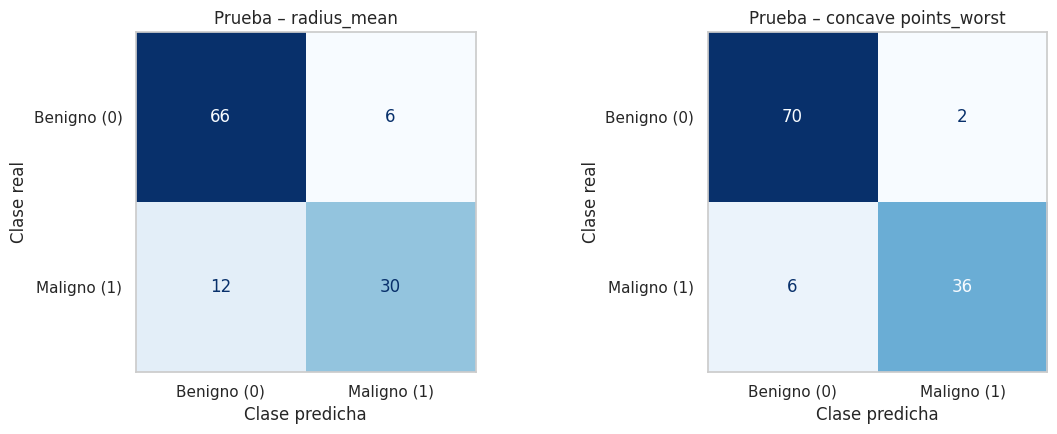

Comparación en prueba (umbral 0,5, clase positiva = maligno)


,radius_mean,concave points_worst
Exactitud,0.842,0.930
Precisión,0.833,0.947
Sensibilidad,0.714,0.857
F1,0.769,0.900


In [53]:
var2 = 'concave points_worst'
X2_train = df.loc[X_train.index, [var2]]
X2_test = df.loc[X_test.index, [var2]]

escalador = StandardScaler().fit(X2_train)          # media y desviación SOLO de entrenamiento
modelo2 = LogisticRegression().fit(escalador.transform(X2_train), y_train)

prob2 = modelo2.predict_proba(escalador.transform(X2_test))[:, 1]   # classes_ = [0 1], columna 1 = maligno
y_pred2 = (prob2 >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pred, titulo in [(axes[0], y_pred, 'radius_mean'), (axes[1], y_pred2, var2)]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),
                           display_labels=['Benigno (0)', 'Maligno (1)']).plot(cmap='Blues', ax=ax, colorbar=False)
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
    ax.set_title(f'Prueba – {titulo}')
    ax.grid(False)
plt.tight_layout()
plt.show()

comparacion = pd.DataFrame({
    'radius_mean': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                    recall_score(y_test, y_pred), f1_score(y_test, y_pred)],
    var2: [accuracy_score(y_test, y_pred2), precision_score(y_test, y_pred2),
           recall_score(y_test, y_pred2), f1_score(y_test, y_pred2)],
}, index=['Exactitud', 'Precisión', 'Sensibilidad', 'F1'])
print('Comparación en prueba (umbral 0,5, clase positiva = maligno)')
comparacion.round(3)

Con `concave points_worst` el modelo mejora en todas las métricas: la exactitud sube de 0,842 a 0,930, la sensibilidad de 0,714 a 0,857 y la precisión de 0,833 a 0,947. Los falsos negativos bajan de 12 a 6 y los falsos positivos de 6 a 2. Esto indica que la **irregularidad del borde** de los núcleos separa mejor las clases que su tamaño. Aun así, sigue siendo una sola variable y todavía se le escapan 6 malignos, así que tampoco sería suficiente por sí sola. El modelo principal de la práctica sigue siendo el de `radius_mean`, como pide la guía; esta parte es solo la comparación opcional.

## 10. Conclusión

- **Desempeño.** Con solo `radius_mean`, la regresión logística acierta el 84,2 % de las muestras de prueba, con precisión de 0,833, sensibilidad de 0,714 y F1 de 0,769. El modelo aprendió una regla sencilla: a mayor radio, mayor probabilidad de maligno, y con el umbral de 0,5 todo radio de 14,79 o más se clasifica como maligno.
- **El punto débil son los falsos negativos.** De 42 malignos en prueba se escaparon 12, todos con radios en la zona donde las dos clases se mezclan. La exactitud se ve buena en parte porque la mayoría de casos son benignos; por eso fue clave mirar la sensibilidad y la precisión.
- **Límites de usar una sola característica.** El radio separa bien los casos extremos, pero entre 10,95 y 17,85 hay muestras de las dos clases y el modelo no tiene más información para distinguirlas. El análisis opcional (sección 9) muestra que otra variable (`concave points_worst`) funciona mejor, lo que confirma que el tamaño por sí solo no describe bien la malignidad. Bajar el umbral reduce los falsos negativos, pero a costa de más falsas alarmas.
- **Alcance.** Este ejercicio evalúa un modelo sobre este dataset en particular, con 114 observaciones de prueba. **No establece su validez para uso clínico**: para eso harían falta más variables, validación con otros pacientes y criterio médico.